<a href="https://colab.research.google.com/github/AmarSai01/nvidia-gpu-ml-jax-labs/blob/main/01_RAPIDS_cuDF_Data_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
import os, requests
os.makedirs("nyc_taxi_data", exist_ok=True)
for m in ["01", "02", "03"]:
    name = f"yellow_tripdata_2024-{m}.parquet"
    path = f"nyc_taxi_data/{name}"
    if not os.path.exists(path):
        r = requests.get(f"https://d37ci6vzurychx.cloudfront.net/trip-data/{name}")
        open(path, "wb").write(r.content)
    print("Downloaded", name)

Mon Oct 26 23:05:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import pandas as pd
df = pd.read_parquet("nyc_taxi_data/yellow_tripdata_2024-03.parquet")
print("Rows:", len(df))
df.describe().round(2)

Rows: 3582628


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,3582628.00,3582628,3582628,3156438.00,3582628.00,3156438.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3582628.00,3156438.00,3156438.00
mean,1.76,2024-03-16 13:36:21.144778,2024-03-16 13:53:01.505050,1.34,4.52,2.26,164.21,163.16,1.08,18.68,1.36,0.48,3.19,0.54,0.97,27.12,2.25,0.14
min,1.00,2002-12-31 22:17:10,2002-12-31 22:42:24,0.00,0.00,1.00,1.00,1.00,0.00,-800.00,-7.50,-0.50,-300.00,-84.30,-1.00,-800.99,-2.50,-1.75
25%,2.00,2024-03-08 20:50:41.750000,2024-03-08 21:05:45.750000,1.00,1.01,1.00,132.00,113.00,1.00,9.30,0.00,0.50,0.00,0.00,1.00,15.48,2.50,0.00
50%,2.00,2024-03-16 10:54:00,2024-03-16 11:08:27,1.00,1.75,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.52,0.00,1.00,20.52,2.50,0.00
75%,2.00,2024-03-23 23:37:26,2024-03-23 23:52:31,1.00,3.30,1.00,233.00,234.00,1.00,21.55,2.50,0.50,4.10,0.00,1.00,29.40,2.50,0.00
max,6.00,2024-04-01 00:34:55,2024-04-02 18:08:46,9.00,176836.30,99.00,265.00,265.00,4.00,900.00,14.25,35.84,999.99,163.00,1.00,1021.99,2.50,1.75
std,0.43,NaN,NaN,0.84,302.41,10.68,64.47,69.57,0.65,18.12,1.81,0.12,4.03,2.16,0.22,22.83,0.84,0.49


Running on CPU...
Running on GPU...
                CPU       GPU
load       3.156145  0.845637
sort       5.822925  0.257388
summarize  1.709733  0.261454
GPU was 7.8x faster!


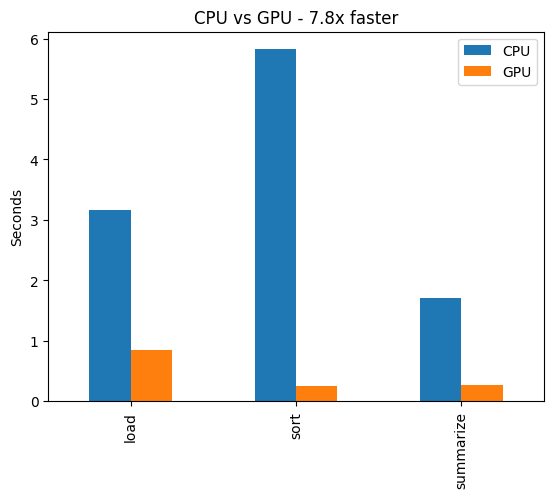

In [ ]:
import time, glob
import pandas as pd
import matplotlib.pyplot as plt

def run_test(pd_module):
    t = {}
    s = time.time()
    df = pd_module.concat([pd_module.read_parquet(f) for f in glob.glob("nyc_taxi_data/*.parquet")], ignore_index=True)
    t["load"] = time.time() - s
    s = time.time()
    df = df.sort_values(["tpep_pickup_datetime", "trip_distance", "passenger_count"], ascending=[False, True, False])
    t["sort"] = time.time() - s
    s = time.time()
    _ = (df.loc[df.tpep_pickup_datetime > "2024-03-01"]
           .groupby(["VendorID", "tpep_pickup_datetime"])[["passenger_count", "fare_amount"]]
           .agg(["min", "mean", "max"]))
    t["summarize"] = time.time() - s
    return t

print("Running on CPU...")
cpu = run_test(pd)
print("Running on GPU...")
%load_ext cudf.pandas
import pandas as gpd
gpu = run_test(gpd)

res = pd.DataFrame([cpu, gpu], index=["CPU", "GPU"]).T
speed = res["CPU"].sum() / res["GPU"].sum()
print(res); print(f"GPU was {speed:.1f}x faster!")
res.plot(kind="bar", title=f"CPU vs GPU - {speed:.1f}x faster")
plt.ylabel("Seconds"); plt.show()

In [ ]:
%%cudf.pandas.profile
import pandas as pd
import glob
df = pd.concat([pd.read_parquet(f) for f in glob.glob("nyc_taxi_data/*.parquet")], ignore_index=True)
df = df.sort_values(["tpep_pickup_datetime", "trip_distance"])
summary = df.groupby("VendorID")[["fare_amount"]].mean()

                                                                                                                  
                                            Total time elapsed: 1.585 seconds                                     
                                          8 GPU function calls in 0.592 seconds                                   
                                          0 CPU function calls in 0.000 seconds                                   
                                                                                                                  
                                                          Stats                                                   
                                                                                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Function                     ┃ GPU ncalls ┃ GPU cumtime ┃ GPU percall ┃ CPU ncalls ┃ CPU cumtime ┃ CPU percall ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ read_parquet                 │ 3          │ 0.352       │ 0.117       │ 0          │ 0.000       │ 0.000       │
│ concat                       │ 1          │ 0.035       │ 0.035       │ 0          │ 0.000       │ 0.000       │
│ DataFrame.sort_values        │ 1          │ 0.097       │ 0.097       │ 0          │ 0.000       │ 0.000       │
│ DataFrame.groupby            │ 1          │ 0.046       │ 0.046       │ 0          │ 0.000       │ 0.000       │
│ DataFrameGroupBy.__getitem__ │ 1          │ 0.005       │ 0.005       │ 0          │ 0.000       │ 0.000       │
│ GroupBy.mean                 │ 1          │ 0.057       │ 0.057       │ 0          │ 0.000       │ 0.000       │
└──────────────────────────────┴────────────┴─────────────┴─────────────┴────────────┴─────────────┴─────────────┘